
## <span style='color:#e91e63'>LAB 9 \(Due Wed, Nov 4 by 11:59pm\). </span>

<span style='color:#e91e63'>For each exercise, answer in the cell below each exercise. Make sure to transfer your answers to Gradescope for your final submission!</span>

<span style='color:#e91e63'><u>Submitting:</u></span><span style='color:#e91e63'> You can keep scratch work in this notebook, but you will submit all your final responses on the assignment linked from D2L, which routes you to Gradescope for your submission. </span>


#### <span style='color:#3f51b5'>Question 0 \(Coding terminology\)</span>

Sometimes differential equations have solutions that are mathematically difficult to determine.  Finding a function with the derivative that we want may not be necessary, so a computer can numerically compute solutions.

The code below uses the Gompertz growth model, which is sometimes used to model the growth of tumors.  The growth of cells is simulated using techniques from modelling general population growth.  The given parameters represent the initial size of the tumor \(initial density of the cells\), the limiting size of the cell density, and the initial rate of tumor growth.  Cancer cells frequently grow in a similar fashion as real\-life populations, which tend to have a very fast initial growth rate and then plateau \(stabilize\) as the population grows. Based on the initial size of the tumor, we can simulate how large we expect a tumor to grow.  The code below is an example of how to solve for the zeros of the Gompertz growth model using two different commands.  You do not need to memorize this model, we are just using it as an applied example.  

**Question 0.1**:  Fill in the asterisks in the first cell to find the roots (zeros) of $X'$.



In [ ]:
#Write a line of code using the solve command for the given function
k = 60 # limiting size of tumor
a = 70 # growth rate
X0 = 10 # initial size of tumor
Xprime(X) = k - a*log(X/X0)  #Change equation for the Gompertz grwoth model
solve(***)  # fill in the asterisks to use the solve command to find the zeros of X'

In [1]:
#copy and paste, then edit your code here
#Write a line of code using the solve command for the given function
k = 60 # limiting size of tumor
a = 70 # growth rate
X0 = 10 # initial size of tumor
Xprime(X) = k - a*log(X/X0)  #Change equation for the Gompertz grwoth model
solve(Xprime,X)  # fill in the asterisks to use the solve command to find the zeros of X'

[X == 10*e^(6/7)]

**Question 0.2:**  Run the following cell to use the ${\tt find\_root()}$ command to find the same zero that you found above, but this time as a numerical estimation instead of an exact value. 

In [2]:
#Run this code
k = 60 # limiting size of tumor
a = 70 # growth rate
X0 = 10 # initial size of tumor
Xprime(X) = k - a*log(X/X0)  #Change equation for the Gompertz grwoth model
find_root(Xprime, 0, 100000) #find the zeros (or roots) of the change equation with the assumption that the zeros are between 0 and 100000)

23.564184423836604

**Question 0.3:**  Run the following cell to display two times series solutions to the Gompertz growth model that use different initial conditions.  What is the connection between the computations you just did in the previous two parts and what you see in the following plot?

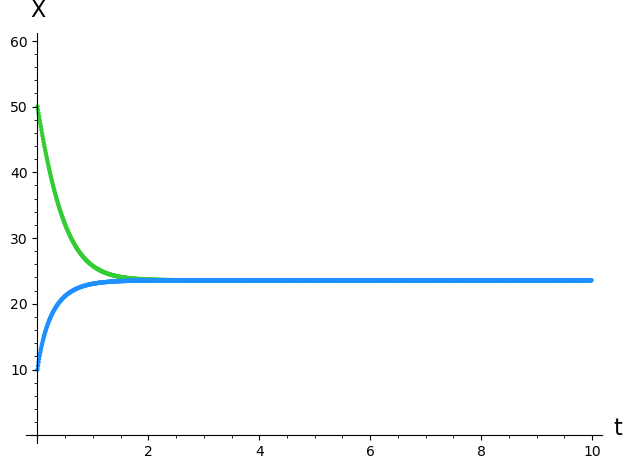

In [3]:
# Compertz Growth model time series graphs

#Run this code cell

# Define our preliminary information (variables, parameters, change equations)
k = 60 # limiting size of tumor
a = 70 # growth rate
X0 = 10 # initial size of tumor
Xprime(X) = k - a*log(X/X0)  #Change equation for the Gompertz grwoth model
t = srange(0, 10, 0.01)

# Simulation 1
GOMPmodel1 = desolve_odeint(Xprime, ics = [50], dvars = [X], times = t)  # Initial value is 50
ts1 = list(zip(t, GOMPmodel1[:,0]))
#show(inital1)

# Simulation 2
GOMPmodel2 = desolve_odeint(Xprime, ics = [10], dvars = [X], times = t)  # Initial size of tumor is 10
ts2 = list(zip(t, GOMPmodel2[:,0]))
#show(inital1)

# Display the two different scenarios side by side
maxpop = 60
initial1 = list_plot(ts1, color = "limegreen", ymin = 0, ymax = maxpop) # Make the time series for the first scenario
initial2 = list_plot(ts2, color = "dodgerblue", ymin = 0, ymax = maxpop, axes_labels=["t","X"] ) # Make the time series for the second scenario
full = initial1 + initial2  # Combine the two plots together
show(full)

#### <span style='font-family:Arial'><span style='color:#3f51b5'>**Questions 1.1-1.7 (Stability of the Allee Effect Model)**</span></span>

In class we introduced a new model that modifies the logistic model by including a factor that symbolizes the need of a minimum population for a species to remain viable.  The Allee Effect model is given by $$X'=rX\left(1-\dfrac{X}{k}\right)\left(\dfrac{X}{a} -1\right)$$ where $r$ is the per capita growth rate, $k$ is the carrying capacity, and $a$ is the minimum population needed for long-term survival.  In this problem we will use a single model  for all the parts, but analyze the stability of its equilibria in each of the ways presented in class.  

The specific model that we will work with has the following conditions:

- $X$ is the number of animals at a point in time
- the population has an 80% growth rate
- the maximum number of animals the environment can support is 100
- there must be at least 20 animals alive for the population to survive long-term.

**Question 1.1:** The first thing we will do is find the equilibrium points of our model.   Remember from our previous labs that Sagemath has a command that will help us solve equations: $\tt{solve( \, )}$.

Define your change equation for our particular Allee Effect model below, naming the function "allee", with uppercase $X$ as the population variable.  Then have Sage solve when the change equation is equal to zero to find the equilibria.  You will upload a screenshot on Gradescope that shows your code and output cell.





In [ ]:
allee(X)= *** # Write the particular Allee Effect Model for the system described above
solve(***)  #fill in the two arguments of the solve command here, using a double equals sign for the equation.  Reminder: You can look back at lab 8 for how to use the solve() command.

In [4]:
#copy and paste the code here
allee(x)= 0.8*x*(1-(x/100))*((x/20)-1) # Write the particular Allee Effect Model for the system described above
solve(allee(x)==0,x)  #fill in the two arguments of the solve command here, using a double equals sign for the equation.  Reminder: You can look back at lab 8 for how to use the solve() command.

[x == 0, x == 20, x == 100]

#### <span style='font-family:Arial'><span style='color:#3f51b5'>**Method of Test Points**</span></span>

**Question 1.2:** Now we use the method of test points to classify the equilibrium points.  Below we have defined the change equation, and we can use it to find the change vector at any population value $X$.  Change the list called $\tt{testpts}$ to have a single test point from each region of our number line. The output of the cell is a list of pairs, with the first coordinate of each pair being the population you chose and the second coordinate being the change vector for that population.   You will upload a screenshot on Gradescope that shows your code and output cell.

It may help to draw the number line on a piece of paper to help you identify the regions and select your test points. 

In [ ]:
allee(X)=0.8*X*(1-(X/100))*((X/20)-1)
testpts=[***] #insert a single test point from each region here, separated by commas

vectors=[] #You do NOT need to add anything to this line of code
pairs=[] #You do NOT need to add anything to this line of code
for i in srange(0,len(testpts)):
    vector=allee(testpts[i])
    vectors.append(vector)
    pairs.append((testpts[i],vectors[i]))
pairs

In [5]:
#copy and paste the code here
allee(X)=0.8*X*(1-(X/100))*((X/20)-1)
testpts=[10,50,150] #insert a single test point from each region here, separated by commas

vectors=[] #You do NOT need to add anything to this line of code
pairs=[] #You do NOT need to add anything to this line of code
for i in srange(0,len(testpts)):
    vector=allee(testpts[i])
    vectors.append(vector)
    pairs.append((testpts[i],vectors[i]))
pairs

[(10, -3.60000000000000), (50, 30.0000000000000), (150, -390.000000000000)]

#### <span style='font-family:Arial'><span style='color:#3f51b5'>**Table of Signs**</span></span>

**Question 1.3:**  Next we use the  Table of Signs method.  This problem will need to be done BY HAND (not in Sagemath).

Use the same change equation as before: $X'=0.8X\left(1-\dfrac{X}{100}\right)\left(\dfrac{X}{20}-1\right)$.

Find the equilibria and classify their stability $\underline{\text{ using the Table of Signs method}}$ from class.  Upload an image of your table to Gradescope.  This problem should be done by hand, not on a computer.  

**_NOTE:_**
- Your table should have **three** columns; one for each of the regions/intervals.
- Your table should have **four** rows; one for each of the three factors, and one at the bottom for the overall sign.
- Clearly state under your table what your conclusions are about the stability of each equilibrium.
- Write your first and last name above your table.
- You need to make your own table.  You may not submit the same exact picture as another student.

In [ ]:
#cell for scratch work

#### <span style='font-family:Arial'><span style='color:#3f51b5'>**Linear Stability Analysis: Graphical**</span></span>

**Question 1.4:**  Now we will do the graphical approach to linear stability analysis.  In this method, we plot the function $X'$ against $X$, then look at the slope of the function at each of the equilibria.  Remember that the equilibria are the $X$ values where $X'=0$, meaning where the graph of the change equation touches the horizontal axis.  
- Plot our function $\tt{allee(X)}$ using the plot command from previous labs.  
- Define a domain for $X$ that starts at zero and reaches a little beyond the largest equilibrium.  
- Include plot options $\tt{ymin} \text{ and } \tt{ymax}$ to make an appropriate viewing window where we can see all the main details of the graph, and $\tt{axes\_labels}$ to label the axes accordingly.   

You will upload a screenshot on Gradescope that shows your code and output cell.

In [ ]:
#Plot the differential equation with an appropriate viewing window and correctly-labeled axes here
allee(X)=0.8*X*(1-(X/100))*((X/20)-1)
plot(***, (X,0,***), ymin=***, ymax=***, color="blue", axes_labels=["***","***"])

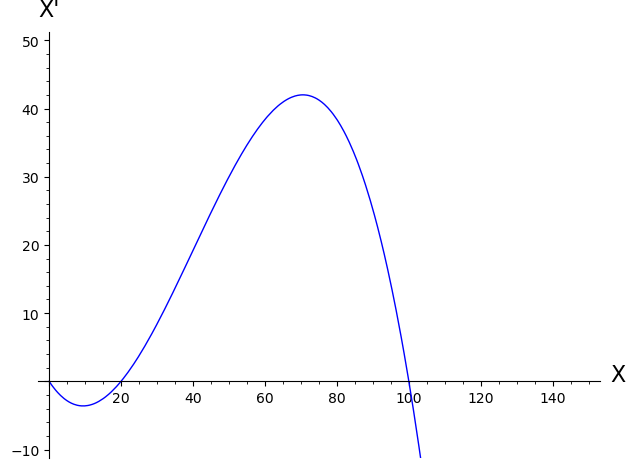

In [6]:
#copy and paste, then edit your code here
#Plot the differential equation with an appropriate viewing window and correctly-labeled axes here
allee(X)=0.8*X*(1-(X/100))*((X/20)-1)
plot(allee, (X,0,150), ymin=-10, ymax=50, color="blue", axes_labels=["X","X'"])

#### <span style='font-family:Arial'><span style='color:#3f51b5'>**Linear Stability Analysis: Computational**</span></span>

**Question 1.5:** We can also verify the stability of the equilibria using our ability to calculate the derivative function to give us the slope at any value.  In particular, we are computing the derivative of $X'$ with respect to $X$.  Recall that we can use the $\tt{diff( ) }$ command from Homework 5 to have Sagemath do this for us.  Then all we need to do is plug in the particular population into the derivative to get the slope at that point.  In the code below, fill in the appropriate commands to have Sage compute the derivative and plug in the equilibrium points into that derivative.  You will upload a screenshot on Gradescope that shows your code and output cell.

In [ ]:
allee(X)=0.8*X*(1-(X/100))*((X/20)-1)
slope(X)=diff(***) ## fill in what should go in the diff command in order to compute the derivative 
eq1 = 0
eq2 = 20
eq3 = 100
x1=slope(***) ## compute the derivative at the left most equilibrium
x2=slope(***) ## compute the derivative at the middle equilibrium
x3=slope(***) ## compute the derivative at the right most equilibrium
print("The slope at X=", eq1, "is", x1)
print("The slope at X=", eq2, "is", x2)
print("The slope at X=", eq3, "is", x3)

In [7]:
#copy and paste, then edit your code here
allee(X)=0.8*X*(1-(X/100))*((X/20)-1)
slope(X)=diff(allee,X) ## fill in what should go in the diff command in order to compute the derivative 
eq1 = 0
eq2 = 20
eq3 = 100
x1=slope(eq1) ## compute the derivative at the left most equilibrium
x2=slope(eq2) ## compute the derivative at the middle equilibrium
x3=slope(eq3) ## compute the derivative at the right most equilibrium
print("The slope at X=", eq1, "is", x1)
print("The slope at X=", eq2, "is", x2)
print("The slope at X=", eq3, "is", x3)

The slope at X= 0 is -0.800000000000000
The slope at X= 20 is 0.640000000000000
The slope at X= 100 is -3.20000000000000


#### <span style='font-family:Arial'><span style='color:#3f51b5'>**Time Series Solutions**</span></span>
**Question 1.6:**  Lastly, we can determine the stability of the equilibrium points using the time series solutions of the change equation.  We will use the same command $\tt{desolve\_odeint}$ from the previous homework to help us find four separate solutions corresponding to four distinct initial populations.  Run the code to see the four solutions on the same plot.

Suppose that you are only given the graph below and that you are not given the equation for this model.  Based on this graph of the time series, why do we know that this model is not the logistic model or a per capita model?  In your response, describe the various behavior that you see in the time series solutions and what this means for the system’s long term behavior for each solution that is displayed. 

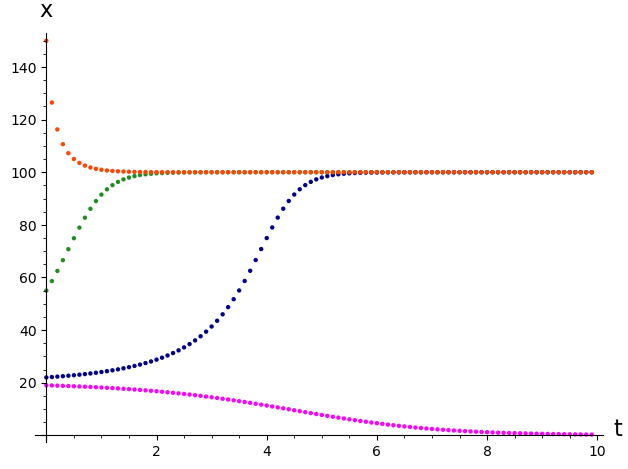

In [8]:
#Solution Curves
allee(x) = 0.8*x*(1-(x/100))*((x/20)-1)

# Approximate from t = 0 to t = 10, with time step of 0.1 (see argument of srange() below)
t = srange(0, 10, 0.1)

# Function to solve and flatten the solution
def solve_and_plot(ics_value, color):
    sol = desolve_odeint(allee(x), ics=[ics_value], times=t, dvars=[x])  # numerically computes the solution X so that X' = allee(x) with initial population the value of ics
    
    # Flatten the array: sol is shape (len(t), 1)
    sol_flat = sol[:, 0].tolist()
    
    return list_plot(list(zip(t, sol_flat)),
                     axes_labels=['t', 'x'],
                     color=color)

DE1 = solve_and_plot(55,  'forestgreen')
DE2 = solve_and_plot(22,  'darkblue')
DE3 = solve_and_plot(150, 'orangered')
DE4 = solve_and_plot(19,  'magenta')
show(DE1+DE2+DE3+DE4)

#### <span style='font-family:Arial'><span style='color:#3f51b5'>**Allee Effect Stability**</span></span>

**Question 1.7:**  We have now computed the stability of the equilibria of this Allee Effect model in $\underline{five}$ different ways.  Since it is the same model in each method, our answers for all five approaches should agree.  Using all the above information, classify the stability of the equilibria of our given model.  _See options on Gradescope_

In [ ]:
# X=0 is stable
# X = 20 is unstable
# X = 100 is stable

#### <span style='font-family:Arial'><span style='color:#3f51b5'>**Questions 2.1-2.4 (Extending Linear Stability Analysis)**</span></span>

In class and earlier in this lab, we ran through the process of using linear stability analysis to classify equilibria as stable or unstable. Below is code for a new change equation called $\tt{change(X)}$, and some tangent lines plotted at the three corresponding equilibria.  Run the code to see the plot.







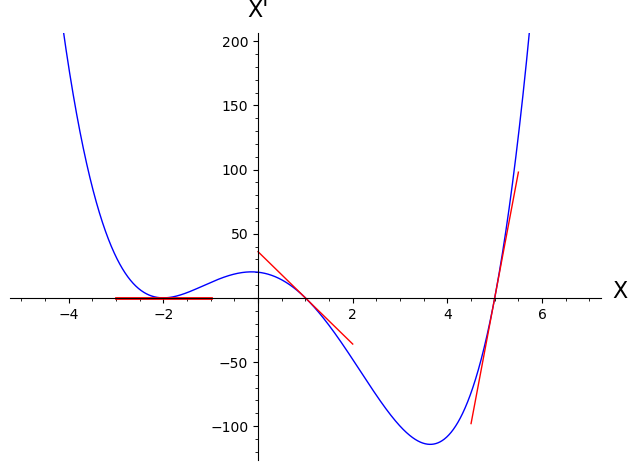

In [9]:
#New change equation for Exercise 2
a=1
b=5
c=-2
change(X)=(X+2)^2*(X-1)*(X-5)
changeprime(X)=diff(change,X)
tanline1(X)=changeprime(a)*(X-a)+change(a)
tanline2(X)=changeprime(b)*(X-b)+change(b)
tanline3(X)=changeprime(c)*(X-c)+change(c)
eqn=plot(change,(X,-5,7), ymin=-120, ymax=200, axes_labels=["X","X'"])
tan1=plot(tanline1,(X,0,2), ymin=-120, ymax=200, color="red")
tan2=plot(tanline2,(X,4.5,5.5), ymin=-120, ymax=200, color="red")
tan3=plot(tanline3,(X,-3,-1), ymin=-120, ymax=200, color="red", thickness=2)
show(eqn+tan1+tan2+tan3)

**Question 2.1:** Classify the stability of the equilibrium points at $X=1$ and $X=5$.


Note that at $X=-2$, the tangent line has a slope of 0, so we can't use the same method of classification as in the previous question.  However, we still can classify the stability if we understand what the graph represents.

**Question 2.2:**  The height of the graph represents the sign of the change vector since this is the graph of $X'$.  For values a little to the left of $X=-2$, what sign is the function and what does that mean about the direction of the change vector?

**Question 2.3:**  For values a little to right of $X=-2$, what sign is the function and what does that mean about the direction of the change vector?

**Question 2.4:**  Based on your answers to 2.2 and 2.3, how would you classify the stability of $X=-2$?

In [ ]:
#2.1: X=1 is stable, X= 5 is unstable
#2.2: function is positive, so change vector points right
#2.3: function is positive, so change vector points right
#2.4: X=-2 is neither

#### <span style='font-family:Arial'><span style='color:#3f51b5'>**Exercise 3.1-2 (Levins Model)**</span></span>

Richard Levins introduced a way to study _metapopulations_ to see the health of the overall population.  A metapopulation is a collection of subpopulations.   Each subpopulation occupies a single patch, and even though a subpopulation may die, the same patch may be repopulated later by migration of a nearby subpopulation.  (You can see his original paper here: http://campus.lakeforest.edu/menke/PDFs/Bio373/Levins_1969_BulEntSocA.pdf)

We let $P$ denote the proportion of patches that are occupied (so $0 \leq P \leq 1)$, $c$ be the colonization rate, and $m$ the mortality rate.  Then the differential equation governing the Levins model is $$P'=cP(1-P) -mP.$$  

One common application of the Levins model is to mosquito populations.  Mosquitoes lay their eggs in pools of still water.  Sometimes predators or humans can wipe out the eggs from a particular pool, but mosquitoes from a nearby water source will just come and repopulate the pool.  Below we will study two main cases: 1) If the mortality rate of mosquitoes is larger than the colonization rate, and 2) if the colonization rate is larger than the mortality rate.

**Exercise 3.1 (Larger Mortality Rate):** Suppose we have the differential equation $$P'=0.5P(1-P)-1.5P.$$  This differential equation has only one equilibrium point in this model (remember, $P$ is the proportion of occupied patches, so $0 \leq P \leq 1$).  Use a command to solve this differential equation for the equilibrium value.  Then on Gradescope, answer the following question.

Why does it make sense that this model has only one equilibrium point?  Give an interpretation based on behavior that we expect in context of the variables and parameters in this model. 

_Reminder:_ We have practiced giving an interpretation of the behavior near an equilibrium point based on its stability in our worksheets for section 3.2, as well as in Quiz 7.






In [ ]:
var('P')
c= 0.5
m=1.5
Levins(P) = c * P * (1-P) - m*P
#add your command here to solve the change equation for the equilibrium points. 

In [10]:
#copy and paste, then edit your code here
var('P')
c= 0.5
m=1.5
Levins(P) = c * P * (1-P) - m*P
solve(Levins(P),P)#add your command here to solve the change equation for the equilibrium points. 

[P == -2, P == 0]

In [ ]:
# The mortality rate is greater than the colonization rate,
# so the mosquitoes are dying faster than they can repopulate
# the empty patches.  In tha case, we would expect the only
# outcome to be that the mosquitoes will all completely die off,
# meaning the only stable equilibrium would be P=0.

**Exercise 3.2 (Larger Colonization Rate):** Suppose we have the differential equation $P'=2P(1-P)-P$.  This differential equation has 2 equilibrium points.  For this problem, enter the last line of code needed to solve for the equilibrium points of this new model. In your written response, classify the stability of the larger population and state the method you used to classify this point.  You will also upload an image (screenshot or by hand) of your work in classifying the point.   

Any screenshot should include both the code and the output cells of Sagemath, and handwritten should show all work.  If using Sage, adapt the code from Questions 1.2, 1.4, 1.5, 1.6 (so excluding the computation of Table of Signs by hand) to determine the stability of your equilibria.  

In [ ]:
var('P')
c= 2
m=1
Levins(P) = c * P*(1-P) - m*P
#add your command here to solve the change equation for the equilibrium points. 

In [11]:
#copy and paste, then edit your code here
var('P')
c= 2
m=1
Levins(P) = c * P*(1-P) - m*P
solve(Levins(P),P)#add your command here to solve the change equation for the equilibrium points. 

[P == (1/2), P == 0]

In [ ]:
# P = 0.5 is stable. 

#### <span style='font-family:Arial'><span style='color:#3f51b5'>**Exercises 4-5 (Exam Reflection) : See Gradescope**</span></span>



